# Tutorial 1: DLPFC data

## Step 1: load needed packages

You need to clone our github repository before running the code.

In [1]:
import os
import copy
import math
import random
import torch
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA

import pandas as pd
import matplotlib.pyplot as plt

import dataprocess as dp
from algorithms import *
from helper import *
import louvain as lv 
import datapreprocess as dpp

## Step 2: define the needed parameters.

Everything is saved in a dictionary called args. 

In [2]:
args = {
            "ngc": 90, # rank
            "nlc":0, # keep it zero
            "num_genes":5000, # number of hvg
            "optim":"SGD", # keep it SGD
            "lr":0.001, # learning rate, I have fine tuned it
            "adaptive":1,
            "shift": 200,
            "lr_SGD":0.001,
            "post_processing_n_component":30,
            "epochs":1000, # number of epochs
            "device": "cuda", 
            "lambda1":0.4, # the regularization parameter, I have fine tuned it
            "lambda2":0.4, # this parameter is not useful for now
            # "group" is a list of list
            "group":[[151507, 151508, 151509, 151510, 151669, 151670, 151671, 151672, 151673, 151674, 151675, 151676]],
            #"group":[[151507], [151508], [151509], [151510], [151669], [151670], [151671], [151672], [151673], [151674], [151675], [151676]],
            "institutions":[[0,1,2,3],[4,5,6,7],[8,9,10,11]],
            #"verbose":11, # the larger you set, the more information the algorithm will output
            "sparse_input":0, # keep it zero
            "spectral_initialization":1, # set it to zero if you want to use random initialization
            "adjacency_scale":0.5, # a parameter in louvain clustering, you don't have to change if you do not choose louvain
            "mclust":"mclust", # mclust seems to be the best
            "spatial_net":"heat", # options are heat and nn
            # heat constructs Gaussian kernel
            # nn constructs mutual nearest neighbor kernel
            "refine":'simplerefine', # don't change the setting
            "proximal":0, # 1 uses proximal gradient descnet, 0 uses standard gradient descent
            'mclustpreprocess':0, # keep it as 0
            'reduceonplateau':1, # keep it as 1
            'logoutput':1, # keep it as 1
            'verbose':13,
            'use_wandb':0,
            'resultfolder':'output1/' # which folder do you want to save the plotted pictures?
        }

## Step 3: read in data and preprocess

You need to put LIBD_All12samples.RDS under the ./data/ folder. The code will read in useful information and separate them into 12 ann data in subanndatalist.

In [3]:
adata_full_raw =  dp.read_fl2_data_adata()
adata_full = adata_full_raw.copy()
subannlist = dpp.preprocess_DLPFC(adata_full,args)
    

loading count data into scipy sparse matrix, this is going to take a while (~7 min)...
Creating names
Creating tensor
sparse matrix constructed in 0.4033 seconds


Then extract highly variable genes in a federated manner, and build the spatial laplacians.

In [4]:
# preprocess
# this function exrtacts highly variable genes
dpp.federated_gene_selection(subannlist,args)
print("High variable genes extracted")

# build spatial laplacian
Ylist, Llist,_,name_list = dpp.build_spatial_kernel(subannlist,args)
name2id = {name_list[i]:i for i in range(len(name_list))}

print("There are %s clients"% len(Ylist))

High variable genes extracted
Median of mean: 6.1658
Median of mean: 6.1658
Median of mean: 6.2556
Median of mean: 6.2108
Median of mean: 6.1658
Median of mean: 6.1658
Median of mean: 6.1658
Median of mean: 6.1658
Median of mean: 6.1658
Median of mean: 6.1658
Median of mean: 6.1658
Median of mean: 6.1658
There are 12 clients


## Step 5: run the federated spatial PCA algorithm

This step is not very time-consuming if you are using cuda. If your preprocessing is appropriate, you should see the loss steadily decrease.

In [5]:
tosave = [torch.tensor(Ylist[i].todense()/100, device=args['device']).float()/100 for i in range(len(Ylist))]


In [15]:
for i in range(len(tosave)):
    data = tosave[i].cpu().numpy().T
    coordinates = subannlist[i].obsm['spatial']
    gt = subannlist[i].obs['ground truth'].values
    # combine coordinates and data and gt
    combined = np.hstack((coordinates, data, gt.reshape(-1,1)))
    print(coordinates.shape, data.shape,gt.shape)
    print(combined.shape)
    # give it a header
    header = ['x', 'y'] + ['gene_%s'%(j) for j in range(data.shape[1])] + ['ground_truth']
    # create a dataframe
    df = pd.DataFrame(combined, columns=header)
    # save data into a csv file
    df.to_csv("fldeploy/datasets/dlpfc/client_%s_data.csv"%(i+1), index=False)
    #break

In [10]:
# dense matrix is faster to compute on cuda
# devide y matrix by 100 to get bettwe condition numbers.
ylists = [torch.tensor(Ylist[i].todense(), device=args['device']).float()/100 for i in range(len(Ylist))]
    
# the main algorithm
# FedSRT spatially resolved transcriptomics
Bg = []
Vg = []
for gid,num_sample in enumerate(args['group']):
    ids = [name2id[name] for name in num_sample ]
    Bgi,Vgi,Bli,Vli = FedSRT([ylists[k]/100 for k in ids], [Llist[k].to(args['device']) for k in ids], args)

    Bg = Bg + Bgi
    Vg = Vg + Vgi

Spectral initialize ...
Spectral initialize completes


## Step 6: post processing

Mclust can take time (around 5 mins on my computer). The average ARI and the picture will appear at the end.

In [11]:
# here we simply normalize each column of Vg
for i in range(len(Vg)):      
    vgi = Vg[i]/torch.norm(Vg[i],dim=1)[:,None]  
    vgi = vgi.detach().cpu().numpy()            
    subannlist[i].obsm['embeddings'] = vgi

If your data does not contain 'ground truth' in its obs, you can randomly generate the ground truth.

adjusted_rand_score: all sample avg 0.5562, 8 sample avg: 0.5315


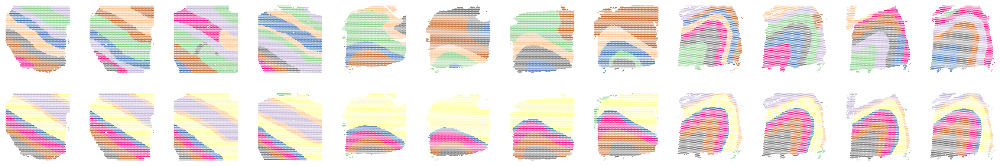

In [12]:
# then run a clustering and visualization code
args['mclust'] = 'mclust'
scores = lv.cluster_and_plot([torch.tensor(subann.obsm['embeddings']) for subann in subannlist],
            [torch.tensor(adata.obsm['spatial']) for adata in subannlist],
            [torch.tensor(adata.obs['ground truth'].values) for adata in subannlist],
            args)
        #plt.savefig('resultfigures/vplots/clusterplot3.png',bbox_inches='tight')
print('-'*40)
for k in scores:
    datak = np.array(scores[k])
    print('%s: all sample avg %.4f, 8 sample avg: %.4f'%(k,np.mean(datak), np.mean(datak[:8])))
plt.show()

On my computer, the average ARI is around 0.56. 
![The clustering plot](resultfigures/vplots/dlpfc_cluster.png)

However, Mclust is very sensitive to small changes in the inputs, therefore your result may differ slightly from mine.

# Gradient attack

First, perform the gradient attack

In [8]:
import gradient_attack_algorithm as ga

vg_recons = ga.gradient_attack(Vg, {"attack_optim":"AdamW", "attack_lr":0.01, "attack_epochs":1000})
for i in range(len(vg_recons)):                
    subannlist[i].obsm['embeddings'] = vg_recons[i].detach().cpu().numpy()


Then, calculate the pearson coefficient between real data and the data reconstructed by the attacker.

1.6452503314975875 0.026533856210626445 3844.0


Text(0.5, 1.0, 'Pearson correlation histogram')

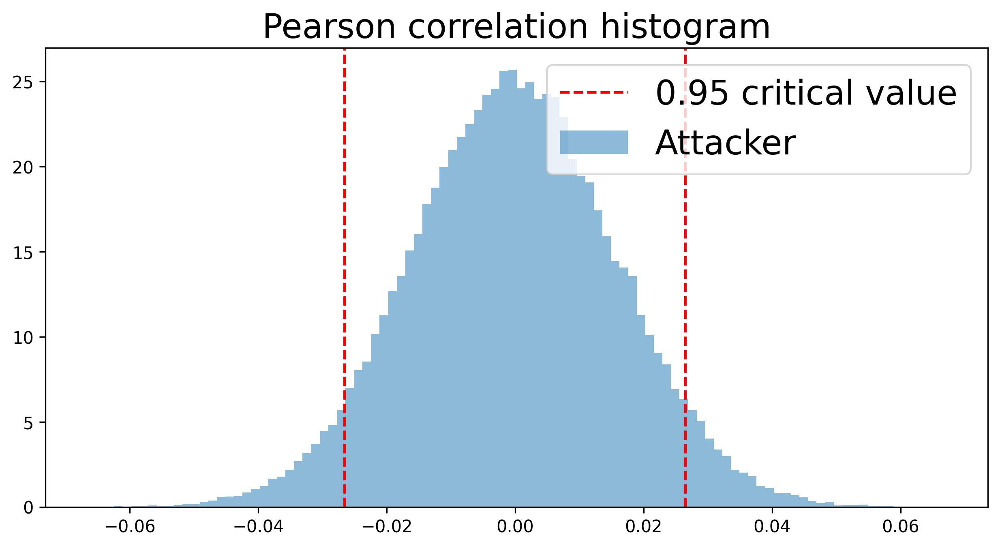

In [9]:
attack_reconstruct = [Bg[i]@vg_recons[i].T for i in range(len(Bg))]
fed_reconstruct =[Bg[i]@Vg[i].T for i in range(len(Bg))]

def pearson(x, y):
    length = []
    def pearsonsingle(x, y):        
        x = x - torch.mean(x,dim=1)[:,None]
        y = y - torch.mean(y,dim=1)[:,None]
        pvalue = torch.sum(x*y,dim=1)/torch.sqrt(1e-10+torch.sum(x**2,dim=1)*torch.sum(1e-10+y**2,dim=1))
        return pvalue, x.shape[1]
    pearsonvalues = []    
    for i in range(len(x)):
        value,n = pearsonsingle(x[i], y[i])
        pearsonvalues.append(value)
        length.append(n)
    pearsonvalues = torch.cat(pearsonvalues)
    return pearsonvalues, length
attack_pearson,lengths = pearson(attack_reconstruct, ylists)
fed_pearson,_ = pearson(fed_reconstruct, ylists)

# t-test
avg_length = np.median(np.array(lengths))
from scipy.stats import t
df = avg_length - 2
quantile = t.ppf(0.95, df)

threshold = 1/math.sqrt(1+1/quantile**2*df)
print(quantile,threshold,avg_length)
# plot pearson correlation histogram
plt.figure(figsize=(10,5),dpi=300)
# Add vertical dashed line at the 0.95 quantile
plt.axvline(x=threshold, color='red', linestyle='--', label=f'0.95 critical value')
plt.axvline(x=-threshold, color='red', linestyle='--')

plt.hist(attack_pearson.detach().cpu().numpy(), density=True,bins=100, alpha=0.5, label='Attacker')
#plt.hist(fed_pearson.detach().cpu().numpy(), density=True,bins=100, alpha=0.5, label='FedSRT')
plt.legend(fontsize=20)
plt.title('Pearson correlation histogram',fontsize=20)

Also, calculate the distance

1.6452503314975875 0.026533856210626445 3844.0


Text(0.5, 1.0, 'Log distance histogram')

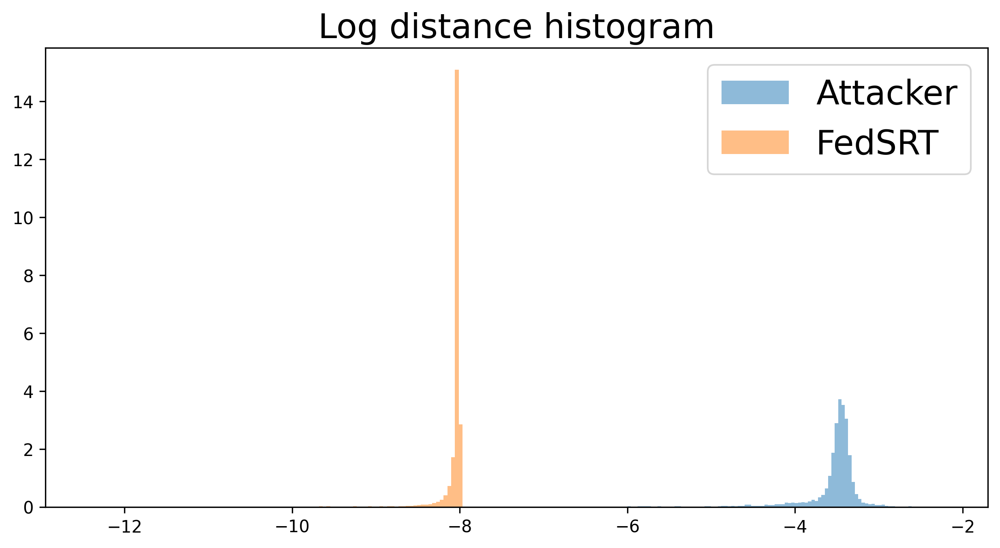

In [10]:
def distance(x, y):
    length = []
    def l2normsq(x, y):             
        return torch.mean((x-y)**2,dim=1), x.shape[1]
    distancevalues = []    
    for i in range(len(x)):
        value,n = l2normsq(x[i], y[i])
        distancevalues.append(value)
        length.append(n)
    distancevalues = torch.cat(distancevalues)
    return distancevalues, length
attack_pearson,lengths = distance(attack_reconstruct, [ylists[k]/100 for k in range(len(ylists))])
fed_pearson,_ = distance(fed_reconstruct, [ylists[k]/100 for k in range(len(ylists))])

# t-test
avg_length = np.median(np.array(lengths))
from scipy.stats import t
df = avg_length - 2
quantile = t.ppf(0.95, df)

threshold = 1/math.sqrt(1+1/quantile**2*df)
print(quantile,threshold,avg_length)
# plot pearson correlation histogram
plt.figure(figsize=(10,5),dpi=300)
# Add vertical dashed line at the 0.95 quantile
#plt.axvline(x=threshold, color='red', linestyle='--', label=f'0.95 critical value')
#plt.axvline(x=-threshold, color='red', linestyle='--')

plt.hist(torch.log(attack_pearson).detach().cpu().numpy()/np.log(10), density=True,bins=100, alpha=0.5, label='Attacker')
plt.hist(torch.log(fed_pearson).detach().cpu().numpy()/np.log(10), density=True,bins=100, alpha=0.5, label='FedSRT')
plt.legend(fontsize=20)
#plt.xlim(xmin=-6, xmax=None) # Set x axis lower bound to 0

plt.title('Log distance histogram',fontsize=20)

Save embeddings to txt file

In [17]:

for i in range(len(subannlist)):
    embeddingi = subannlist[i].obsm['embeddings']
    embeddingi = np.concatenate((embeddingi, subannlist[i].obsm['spatial']), axis=1)  # add a zero column
    cols=[f'factor_{j}' for j in range(subannlist[i].obsm['embeddings'].shape[1])] + ['x', 'y']
    
    df = pd.DataFrame(embeddingi, columns=cols)
    df.to_csv(f'resultstoplot/attack_embeddings_{i}.csv', index=False)

Plot the clusters

adjusted_rand_score: all sample avg -0.0008, 8 sample avg: -0.0009


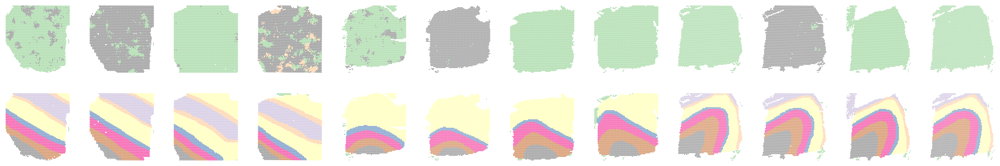

In [18]:
scores = lv.cluster_and_plot([torch.tensor(subann.obsm['embeddings']) for subann in subannlist],
            [torch.tensor(adata.obsm['spatial']) for adata in subannlist],
            [torch.tensor(adata.obs['ground truth'].values) for adata in subannlist],
            args)
        #plt.savefig('resultfigures/vplots/clusterplot3.png',bbox_inches='tight')
print('-'*40)
for k in scores:
    datak = np.array(scores[k])
    print('%s: all sample avg %.4f, 8 sample avg: %.4f'%(k,np.mean(datak), np.mean(datak[:8])))
plt.show()

Next, plot Marker genes 

In [18]:
import rpy2.robjects as robjects
data = robjects.r['readRDS']('data/LIBD_All12samples.RDS')
rowData_of_data = robjects.r['rowData'](data)
rowdatanames = list(robjects.r.names(rowData_of_data.slots['listData']))
genename = np.array(rowData_of_data.slots['listData'][rowdatanames.index('gene_name')])


Done!


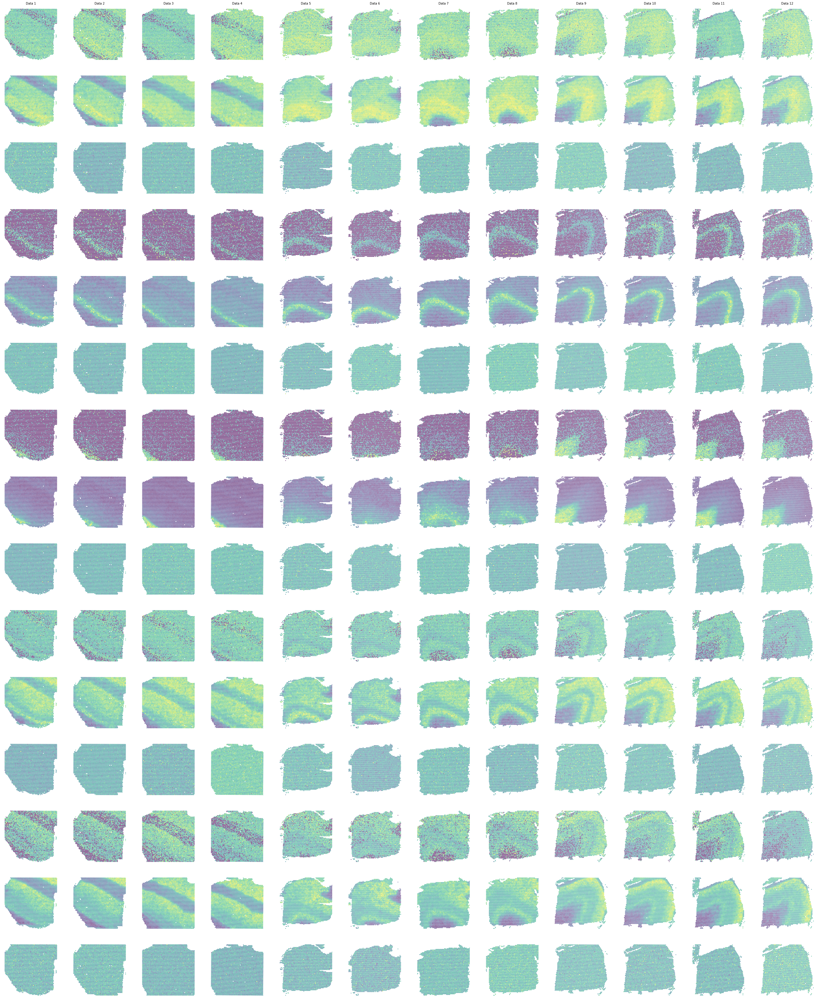

In [25]:
markergenes = ['SNAP25', 'PCP4','MOBP','CCK','ENC1']
# plot all marker genes
figs, axs = plt.subplots(3*len(markergenes), 12, figsize=(12*4, 3*4*len(markergenes)))
hvg_id_list = subannlist[0].var['highly_variable'].to_numpy()
ps = 1
datatosave = {i: [] for i in range(12)}
titlelist = []
for i,mk in enumerate(markergenes):
    titlelist = titlelist + [mk+"_GT", mk+"_Fed", mk+"_Attack"]
    indices = np.where(genename == mk)[0]
    if len(indices)==0:
        continue
    indices = indices[0]
    if hvg_id_list[indices] == False:
        print(f"Warning: Marker gene {mk} is not selected in the highly variable genes list.")
        continue
    gid = sum(hvg_id_list[:indices])
    for j in range(12):
        # Original
        axs[i*3, j].scatter(
            subannlist[j].obsm['spatial'][:,0],
            -subannlist[j].obsm['spatial'][:,1],
            c=ylists[j][gid].detach().cpu().numpy(),
            cmap='viridis', s=ps
        )
        axs[i*3, j].axis('off')
        if j == 0:
            axs[i*3, j].set_ylabel(f"{mk}\nOriginal", fontsize=10, rotation=0, labelpad=40, va='center')

        # Fed Reconstruct
        axs[i*3+1, j].scatter(
            subannlist[j].obsm['spatial'][:,0],
            -subannlist[j].obsm['spatial'][:,1],
            c=fed_reconstruct[j][gid].detach().cpu().numpy(),
            cmap='viridis', s=ps
        )
        axs[i*3+1, j].axis('off')
        if j == 0:
            axs[i*3+1, j].set_ylabel("Fed", fontsize=10, rotation=0, labelpad=40, va='center')

        # Attack Reconstruct
        axs[i*3+2, j].scatter(
            subannlist[j].obsm['spatial'][:,0],
            -subannlist[j].obsm['spatial'][:,1],
            c=attack_reconstruct[j][gid].detach().cpu().numpy(),
            cmap='viridis', s=ps
        )
        axs[i*3+2, j].axis('off')
        if j == 0:
            axs[i*3+2, j].set_ylabel("Attack", fontsize=10, rotation=0, labelpad=40, va='center')

        # Column titles for dataset index
        if i == 0:
            axs[0, j].set_title(f"Data {j+1}", fontsize=10)

        dataj = np.stack([ylists[j][gid].detach().cpu().numpy(),
                                fed_reconstruct[j][gid].detach().cpu().numpy(),
                                attack_reconstruct[j][gid].detach().cpu().numpy()],axis=1)
        datatosave[j].append(dataj)

titlelist = ['x', 'y'] + titlelist
for j in range(12):
    datatosave[j] = np.concatenate(datatosave[j],axis=1)
    
    df = pd.DataFrame(np.concatenate([subannlist[j].obsm['spatial'],datatosave[j]],axis=1), columns=titlelist)
    df.to_csv(f'resultstoplot/marker_gene_in_sample_{j}.csv', index=False)
SAVEFIG = False
if SAVEFIG:
    plt.tight_layout()
    plt.savefig("marker_gene_panel.png", dpi=300)
    #plt.show()
print("Done!")